In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uncertainties

In [4]:
df = pd.read_csv("run_1_roomtemp.csv")
df.head()

,V_Copper,V_Sapphire,time,sensor_temperature,temperature_setpoint,iTC_P_param,iTC_I_param,iTC_D_param
0,-0.000002,-0.000002,0.000000,295.0473,6.0,1.0,0.0,0.0
1,-0.000002,-0.000002,0.224226,295.0472,6.0,1.0,0.0,0.0
2,-0.000002,-0.000002,0.483922,295.0472,6.0,1.0,0.0,0.0
3,-0.000002,-0.000002,0.733948,295.0472,6.0,1.0,0.0,0.0
4,-0.000002,-0.000002,0.949890,295.0472,6.0,1.0,0.0,0.0


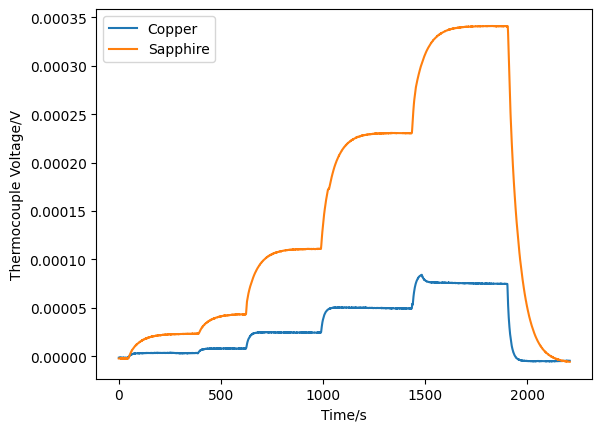

In [7]:
time = df['time']
v_cop = df['V_Copper']
v_sap = df['V_Sapphire']

plt.plot(time, v_cop, label = 'Copper')
plt.plot(time, v_sap, label = 'Sapphire')
plt.legend()
plt.xlabel("Time/s")
plt.ylabel("Thermocouple Voltage/V")
plt.show()

In [16]:
windows = {
    "V_Copper":   [(0, 45), (100, 385), (450, 618), (700, 985), (1060, 1430), (1560, 1900), (2000, 2205)],
    "V_Sapphire": [(0, 45), (245, 387), (555, 618), (850, 985), (1250, 1430), (1690, 1900), (2100, 2205)],
}
v_avg = {}
v_std = {}

for material, times in windows.items():
    print(material)
    v_avg[material] = []
    v_std[material] = []
    for start, end in times:
        in_window = (time >= start) & (time <= end)
        average = df.loc[in_window, material].mean()
        std = df.loc[in_window, material].std()
        v_avg[material].append(average)
        v_std[material].append(std)
        print(f"  {start}-{end} s: {average:.4e} +- {std:.4e} V")

V_Copper
  0-45 s: -1.5805e-06 +- 5.7074e-08 V
  100-385 s: 3.3195e-06 +- 9.8973e-08 V
  450-618 s: 7.9395e-06 +- 6.3574e-08 V
  700-985 s: 2.4532e-05 +- 1.3008e-07 V
  1060-1430 s: 4.9828e-05 +- 3.1376e-07 V
  1560-1900 s: 7.5310e-05 +- 3.9295e-07 V
  2000-2205 s: -4.9974e-06 +- 1.1336e-07 V
V_Sapphire
  0-45 s: -2.3047e-06 +- 6.0724e-08 V
  245-387 s: 2.2974e-05 +- 2.0133e-07 V
  555-618 s: 4.3113e-05 +- 1.7213e-07 V
  850-985 s: 1.1061e-04 +- 1.9489e-07 V
  1250-1430 s: 2.3033e-04 +- 2.0376e-07 V
  1690-1900 s: 3.4074e-04 +- 2.6316e-07 V
  2100-2205 s: -2.8319e-06 +- 2.3205e-06 V


In [ ]:
baseline = {
    "V_Copper": v_avg["V_Copper"][0],
    "V_Sapphire": v_avg["V_Sapphire"][0]
}

v_avg_adj = {}

for material in v_avg.keys():
    v_avg_adj[material] = []
    #print(material)
    for i in range(1, len(v_avg[material])-1):
        v_avg_adj[material].append(v_avg[material][i]-baseline[material])
for material, values in v_avg_adj.items():
    print(material)
    for i, v in enumerate(values, start=1):
        print(f"  Step {i}: {v:.4e} V")




V_Copper
V_Sapphire
V_Copper
  Step 1: 4.9000e-06 V
  Step 2: 9.5200e-06 V
  Step 3: 2.6113e-05 V
  Step 4: 5.1408e-05 V
  Step 5: 7.6891e-05 V
V_Sapphire
  Step 1: 2.5278e-05 V
  Step 2: 4.5418e-05 V
  Step 3: 1.1291e-04 V
  Step 4: 2.3264e-04 V
  Step 5: 3.4305e-04 V
